# Detecção de macrófagos em imagens parasitológicas de LV canina

* Este método utiliza a YOLO v8 em imagens de duas lâminas (uma saudável e outra infectada)
* O dataset já se encontra devidamente anotado e convertido para o formato usado pelo YOLO

# Utilização da GPU

In [1]:
!nvidia-smi

Thu Feb 15 01:26:21 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.154.05             Driver Version: 535.154.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA GeForce RTX 2080 Ti     Off | 00000000:09:00.0 Off |                  N/A |
|  0%   39C    P8               5W / 300W |      6MiB / 11264MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [2]:
import os
# os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
# os.environ["CUDA_VISIBLE_DEVICES"]="0" #aqui tem q escolher uma das gpus, veja a que esta desocupada
# tf_device='/gpu:0'

# Importação das bibliotecas

In [3]:
from ultralytics import YOLO
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from datetime import datetime
import csv

import warnings
warnings.filterwarnings('ignore')

In [4]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Clésio Gonçalves" --iversions
!python --version
!conda -V

Author: Clésio Gonçalves

pandas    : 2.1.4
numpy     : 1.26.4
csv       : 1.0
cv2       : 4.9.0
matplotlib: 3.8.0

Python 3.11.5
/bin/bash: linha 1: conda: comando não encontrado


In [5]:
import torch
torch.cuda.is_available()

True

# Estrutura do Dataset
* /dataset_yolo
  * /train
  * /valid

# Configurações do arquivo YAML

In [6]:
arquivo_config = "configuracoes_modelo.yaml"

Preencher esse arquivo com os parâmetros necessários

* path: [caminho do diretório que contém o dataset]
* train: [caminho do conjunto de treinamento, relativo ao path]
* val: [caminho do conjunto de validação, relativo ao path]
* test: [caminho do conjunto de testes, relativo ao path]

**Número de Classes**
* nc: [numero de classes de treinamento]

**Nomes/Labels - substitua pelos nomes das classes**
* names: [nome de cada classe, dentro de '' e separado por vírgula]

Para escrever esses valores no arquivo, podemos usar o comando %%writefile

In [7]:
diretorio_raiz = os.getcwd()

In [8]:
# Cria o arquivo configuracoes_modelo.yaml
caminho_arquivo_config = os.path.join(diretorio_raiz, arquivo_config)
with open(caminho_arquivo_config, 'w') as arquivo:
    arquivo.write(f"path: {diretorio_raiz}/dataset_yolo/\n")
    arquivo.write("train: train/\n")
    arquivo.write("val: valid/\n")
    arquivo.write("test: # opcional\n\n")
    arquivo.write("nc: 2\n")
    arquivo.write("names: ['macrophage', 'Non-macrophages']\n")

# Treinamento do modelo

> **Parâmetros da função de treinamento:**

* **task**: o que será executado com o treinamento. Como é detecção de objetos, deixe o valor = detect. Outras opções aceitas: segment, e classify. É opcional passarmos se queremos detecção, pois por padrão ele já considera como sendo detecção a não ser que especifique outra forma.
* **mode**: pode ser train, val, ou predict. Como estamos fazendo pela forma usando python e queremos o treinamento vamos usar a função train(), portanto esse parâmetro se torna desnecessário .
* **model**: o modelo pré-treinado que queremos usar como "partida". São disponibilizados 5 modelos: YOLOv8n (nano), YOLOv8s (small), YOLOv8m (medium), YOLOv8l (large), YOLOv8x (extra large). Nano é o mais rápido e o menor (menos pesado para rodar), enquanto que o Extra Large (YOLOv8x) é o mais preciso porém mais pesado para rodar, portanto será mais lento. Para o valor desse parâmetro, basta informar o nome e ao lado .pt pois é a extensão do modelo treinado em pytorch.
* **imgsz**: O tamanho da imagem, que a rede realiza o processamento (obs: você não precisa redimensionar a imagem para esse tamanho antes, o algoritmo cuida dessa parte antes de passar a imagem de entrada para a rede). A resolução padrão é 640x640 pixels, portanto o valor padrão é 640. Quando maior o tamanho mais precisa é a detecção, principalmente para objetos com detalhes pequenos, porém é mais demorado o treinamento e detecção.  
* **data**: caminho para o arquivo YAML. Esse é o arquivo que foi criado acima, que contém o caminho para o conjunto de treinamento e validaçao, além disso deve conter os nomes das classes que queremos treinar.
* **epochs**: Numero de epocas que desejamos treinar.
* **batch**: O tamanho do batch (lote) para o carregador de dados. Você pode aumentá-lo ou diminuí-lo de acordo com a disponibilidade de memória de sua GPU, por exemplo caso venha a encontrar problema de memória. O valor padrão é 16.
* **name**: Nome do diretório de resultados para o runs/detect. (opcional)
* **device**: usar várias GPU. exemplo: device=[0, 1]

In [9]:
#Fonte: https://docs.ultralytics.com/pt/modes/train/#usage-examples

# model = YOLO('yolov8x.yaml') # build a new model from YAML
model = YOLO('yolov8x.pt') # load a pretrained model (recommended for training)
# model = YOLO('yolov8x.yaml').load('yolov8x.pt') # build from YAML and transfer weights

In [10]:
resultados = model.train(
    data = arquivo_config, 
    epochs=200, 
    name='yolov8x_modelo', 
    batch=9,
    imgsz=640,
    device=[0, 1, 2])

Ultralytics YOLOv8.1.14 🚀 Python-3.11.5 torch-2.2.0 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11012MiB)
                                                     CUDA:1 (NVIDIA GeForce RTX 2080 Ti, 11012MiB)
                                                     CUDA:2 (NVIDIA GeForce RTX 2080 Ti, 11009MiB)
engine/trainer: task=detect, mode=train, model=yolov8x.pt, data=configuracoes_modelo.yaml, epochs=200, time=None, patience=50, batch=9, imgsz=640, save=True, save_period=-1, cache=False, device=[0, 1, 2], workers=8, project=None, name=yolov8x_modelo3, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=Fal

2024-02-15 01:26:47.934337: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-15 01:26:47.934379: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-15 01:26:47.935540: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1      2320  ultralytics.nn.modules.conv.Conv             [3, 80, 3, 2]                 
  1                  -1  1    115520  ultralytics.nn.modules.conv.Conv             [80, 160, 3, 2]               
  2                  -1  3    436800  ultralytics.nn.modules.block.C2f             [160, 160, 3, True]           
  3                  -1  1    461440  ultralytics.nn.modules.conv.Conv             [160, 320, 3, 2]              
  4                  -1  6   3281920  ultralytics.nn.modules.block.C2f             [320, 320, 6, True]           
  5                  -1  1   1844480  ultralytics.nn.modules.conv.Conv             [320, 640, 3, 2]              
  6                  -1  6  13117440  ultralytics.nn.modules.block.C2f             [640, 640, 6, True]           
  7                  -1  1   3687680  ultralytics

*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************


Ultralytics YOLOv8.1.14 🚀 Python-3.11.5 torch-2.2.0 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11012MiB)
                                                     CUDA:1 (NVIDIA GeForce RTX 2080 Ti, 11012MiB)
                                                     CUDA:2 (NVIDIA GeForce RTX 2080 Ti, 11009MiB)


[W Utils.hpp:164] Warning: Environment variable NCCL_BLOCKING_WAIT is deprecated; use TORCH_NCCL_BLOCKING_WAIT instead (function getCvarBool)
[W Utils.hpp:164] Warning: Environment variable NCCL_BLOCKING_WAIT is deprecated; use TORCH_NCCL_BLOCKING_WAIT instead (function getCvarBool)
2024-02-15 01:26:54.040094: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-15 01:26:54.040140: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-15 01:26:54.041229: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
[W Utils.hpp:164] Warning: Environment variable NCCL_BLOCKING_WAIT is deprecated;

... (155 outputs left out)

     77/200      4.18G     0.7013     0.4122     0.8562         16        640: 100%|██████████| 59/59 [00:19<00:00,  3.00it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 22/22 [00:01<00:00, 16.43it/s]


                   all        132        279      0.687      0.706      0.718      0.514
Stopping training early as no improvement observed in last 50 epochs. Best results observed at epoch 27, best model saved as best.pt.
To update EarlyStopping(patience=50) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

77 epochs completed in 0.628 hours.
Optimizer stripped from runs/detect/yolov8x_modelo3/weights/last.pt, 136.7MB
Optimizer stripped from runs/detect/yolov8x_modelo3/weights/best.pt, 136.7MB

Validating runs/detect/yolov8x_modelo3/weights/best.pt...
Ultralytics YOLOv8.1.14 🚀 Python-3.11.5 torch-2.2.0 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11012MiB)
                                                     CUDA:1 (NVIDIA GeForce RTX 2080 Ti, 11012MiB)
                                                     CUDA:2 (NVIDIA GeForce RTX 2080 Ti, 11009MiB)
Model summary (fused): 268 layers, 68125494 parameters, 0 gradients, 257.4 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 22/22 [00:01<00:00, 16.49it/s]


                   all        132        279      0.692      0.771      0.765      0.537
            macrophage        132         82      0.638      0.756      0.691      0.496
       Non-macrophages        132        197      0.747      0.787      0.839      0.577
Speed: 0.2ms preprocess, 6.6ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to runs/detect/yolov8x_modelo3


## Avaliação  (Verificando o mAP do modelo)

In [11]:
# Nome do modelo
nome_modelo = 'yolov8x_modelo3'
dir_resultado = os.path.join(diretorio_raiz, 'runs/detect', nome_modelo)

In [12]:
!yolo task=detect mode=val model={dir_resultado}/weights/best.pt name={nome_modelo}_eval data={caminho_arquivo_config}

Ultralytics YOLOv8.1.14 🚀 Python-3.11.5 torch-2.2.0 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11012MiB)
Model summary (fused): 268 layers, 68125494 parameters, 0 gradients, 257.4 GFLOPs
val: Scanning /media/pavic/dados1/clesio/deteccao-macrofago/dataset_yolo/valid.c
                 Class     Images  Instances      Box(P          R      mAP50  m
                   all        132        279       0.69      0.769      0.765      0.538
            macrophage        132         82      0.636      0.756       0.69      0.497
       Non-macrophages        132        197      0.743      0.782      0.839      0.578
Speed: 1.3ms preprocess, 12.7ms inference, 0.0ms loss, 4.0ms postprocess per image
Results saved to runs/detect/yolov8x_modelo3_eval
💡 Learn more at https://docs.ultralytics.com/modes/val


## Exibindo os gráficos

In [13]:
def mostrar(img):
  fig = plt.gcf()
  fig.set_size_inches(16, 10)
  plt.axis("off")
  plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  plt.show()

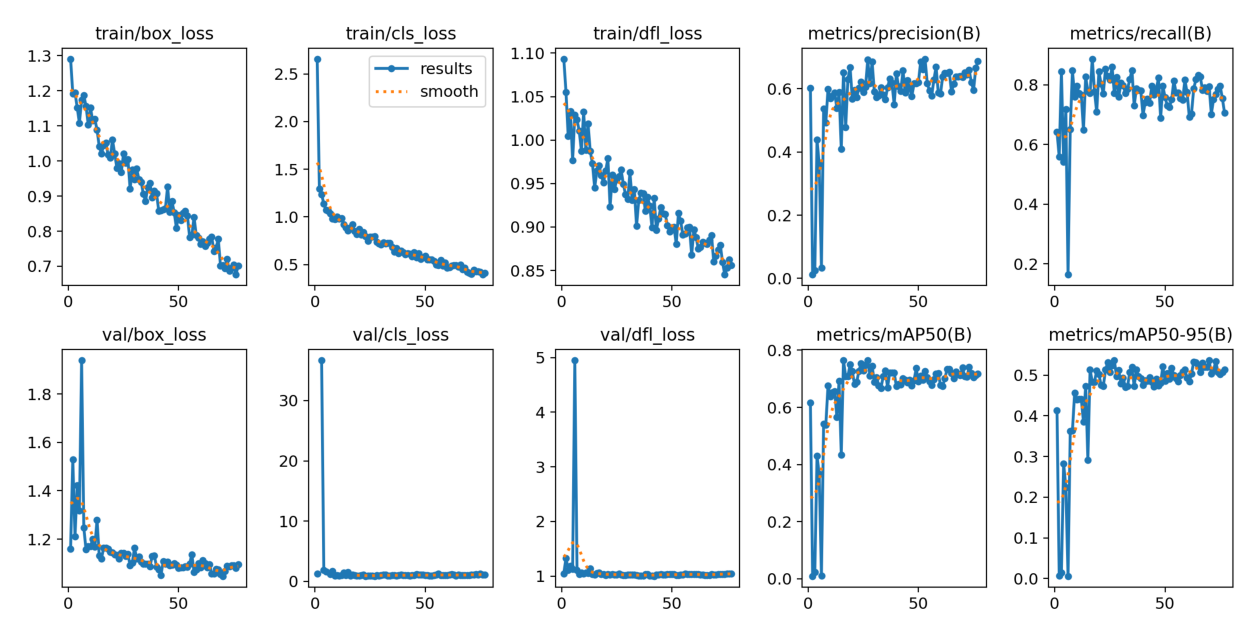

In [14]:
resultados_grafico = cv2.imread(os.path.join(dir_resultado, "results.png"))
mostrar(resultados_grafico)

In [15]:
dir_resultado_val = f'runs/detect/{nome_modelo}_eval'

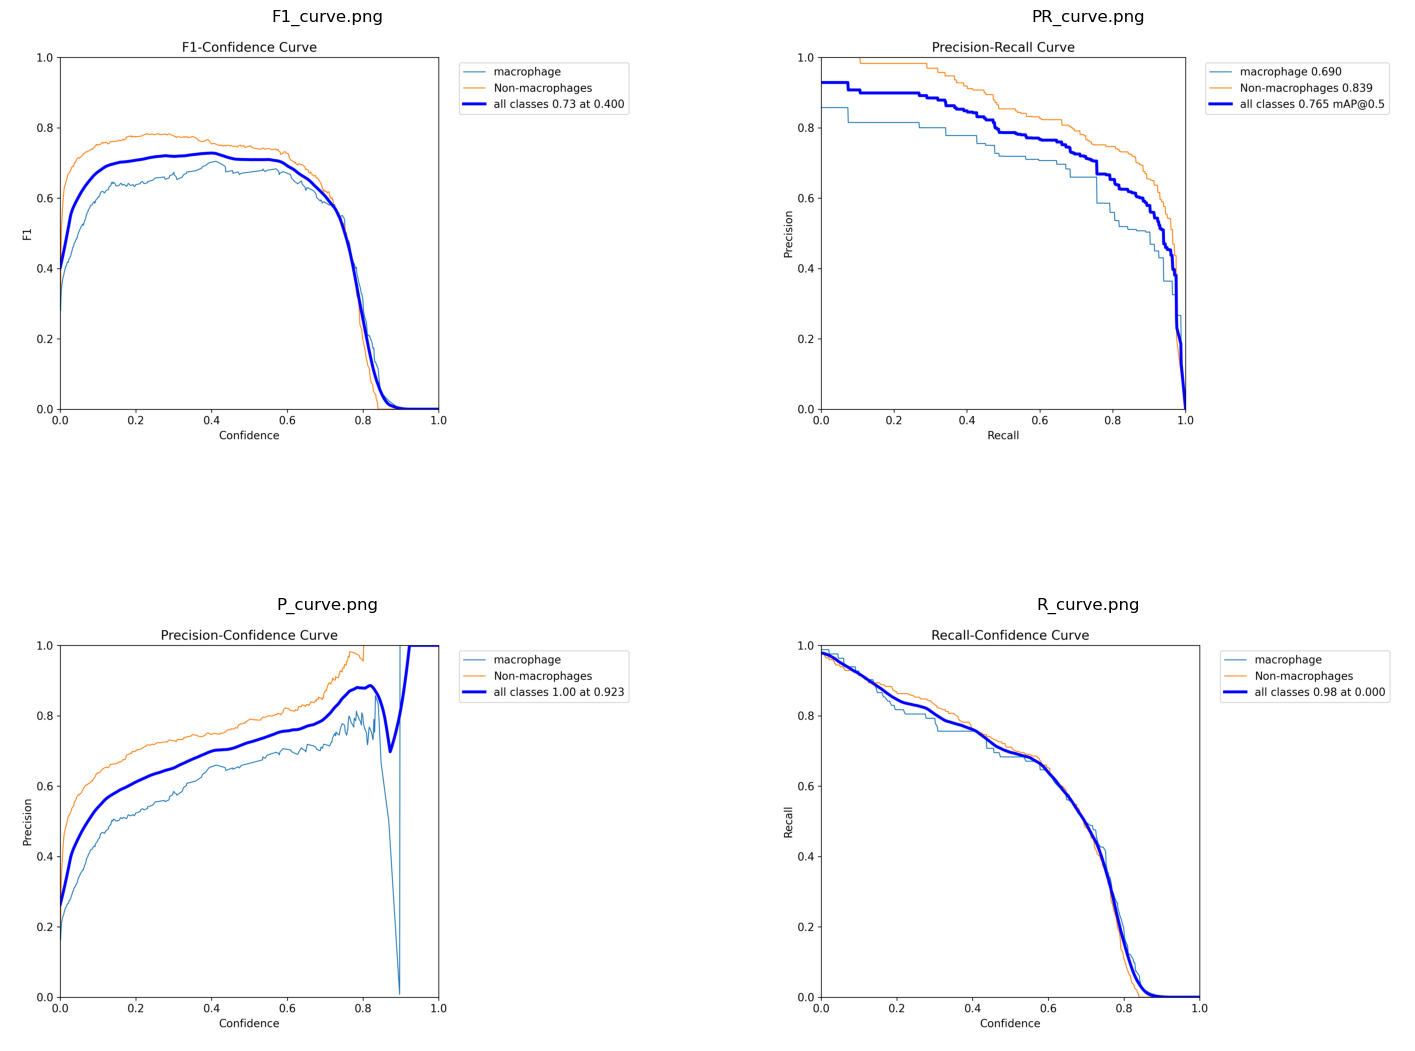

In [16]:
imgs = ['F1_curve.png', 'PR_curve.png', 'P_curve.png', 'R_curve.png']
plt.figure(figsize=(18,14))
for i, img in enumerate(imgs):
    grafico = cv2.imread(os.path.join(dir_resultado_val, img))
    grafico = cv2.cvtColor(grafico, cv2.COLOR_BGR2RGB)
    plt.subplot(2, 2, i + 1)
    plt.title(imgs[i])
    plt.imshow(grafico)
    plt.axis('off')
plt.show()

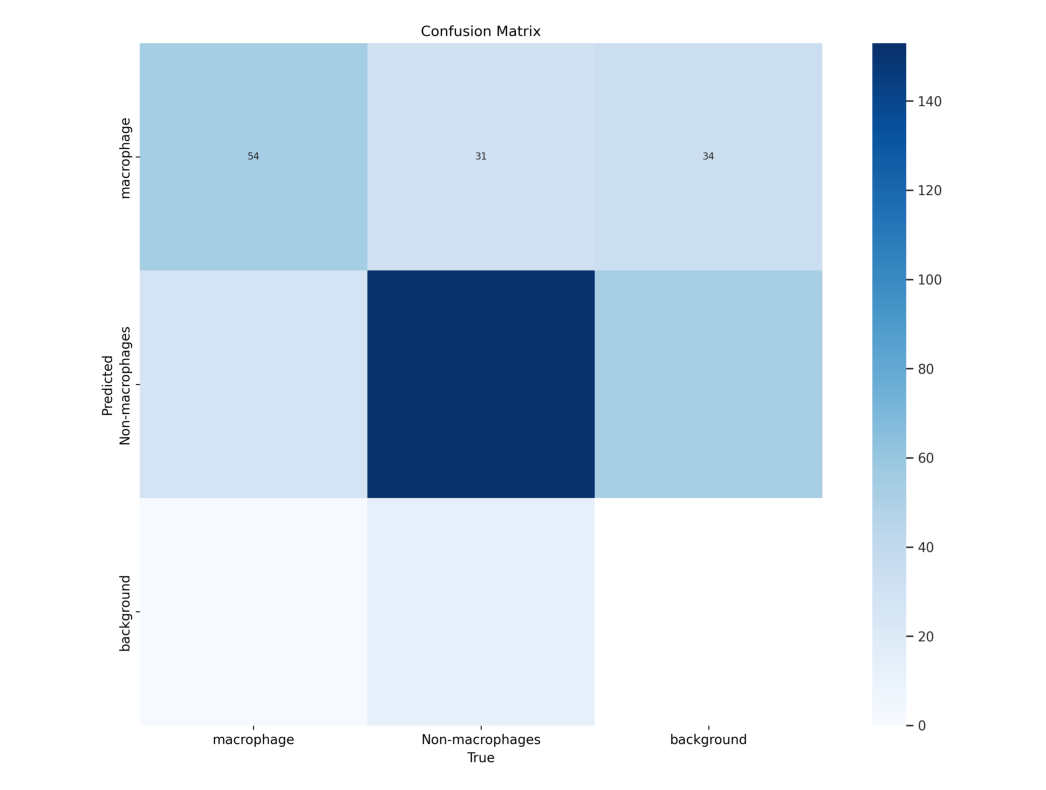

In [17]:
matriz_confusao = cv2.imread(os.path.join(dir_resultado_val, 'confusion_matrix.png'))
mostrar(matriz_confusao)

# Testando o modelo treinado

In [18]:
!yolo task=detect mode=predict model={dir_resultado}/weights/best.pt source="teste-predicoes" save=true

Ultralytics YOLOv8.1.14 🚀 Python-3.11.5 torch-2.2.0 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11012MiB)
Model summary (fused): 268 layers, 68125494 parameters, 0 gradients, 257.4 GFLOPs

image 1/5 /media/pavic/dados1/clesio/deteccao-macrofago/teste-predicoes/a11_mo_f_l1_109.png: 384x640 2 Non-macrophagess, 52.1ms
image 2/5 /media/pavic/dados1/clesio/deteccao-macrofago/teste-predicoes/a11_mo_f_l1_116.png: 384x640 1 Non-macrophages, 20.9ms
image 3/5 /media/pavic/dados1/clesio/deteccao-macrofago/teste-predicoes/a11_mo_f_l1_125.png: 384x640 1 Non-macrophages, 20.8ms
image 4/5 /media/pavic/dados1/clesio/deteccao-macrofago/teste-predicoes/a11_mo_f_l1_129.png: 384x640 1 Non-macrophages, 20.9ms
image 5/5 /media/pavic/dados1/clesio/deteccao-macrofago/teste-predicoes/a11_mo_f_l1_138.png: 384x640 1 macrophage, 2 Non-macrophagess, 20.9ms
Speed: 1.9ms preprocess, 27.1ms inference, 68.1ms postprocess per image at shape (1, 3, 384, 640)
Results saved to runs/detect/predict3
💡 Learn more at https://docs.ult

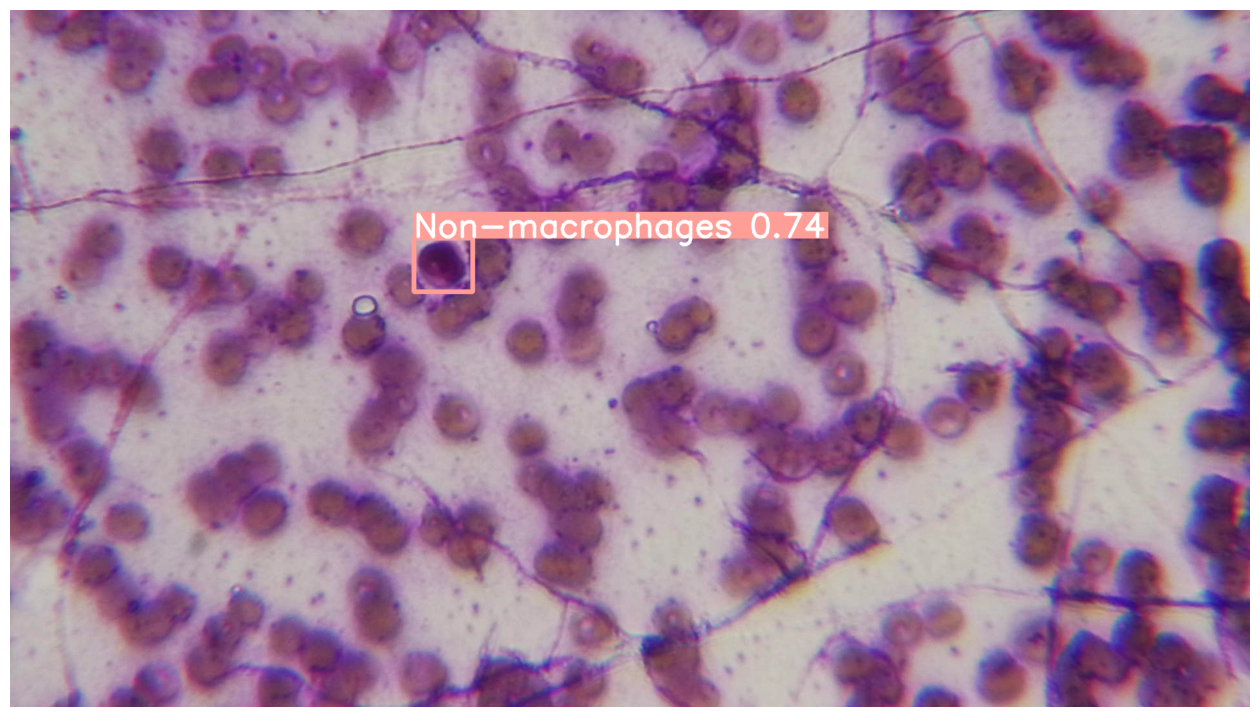

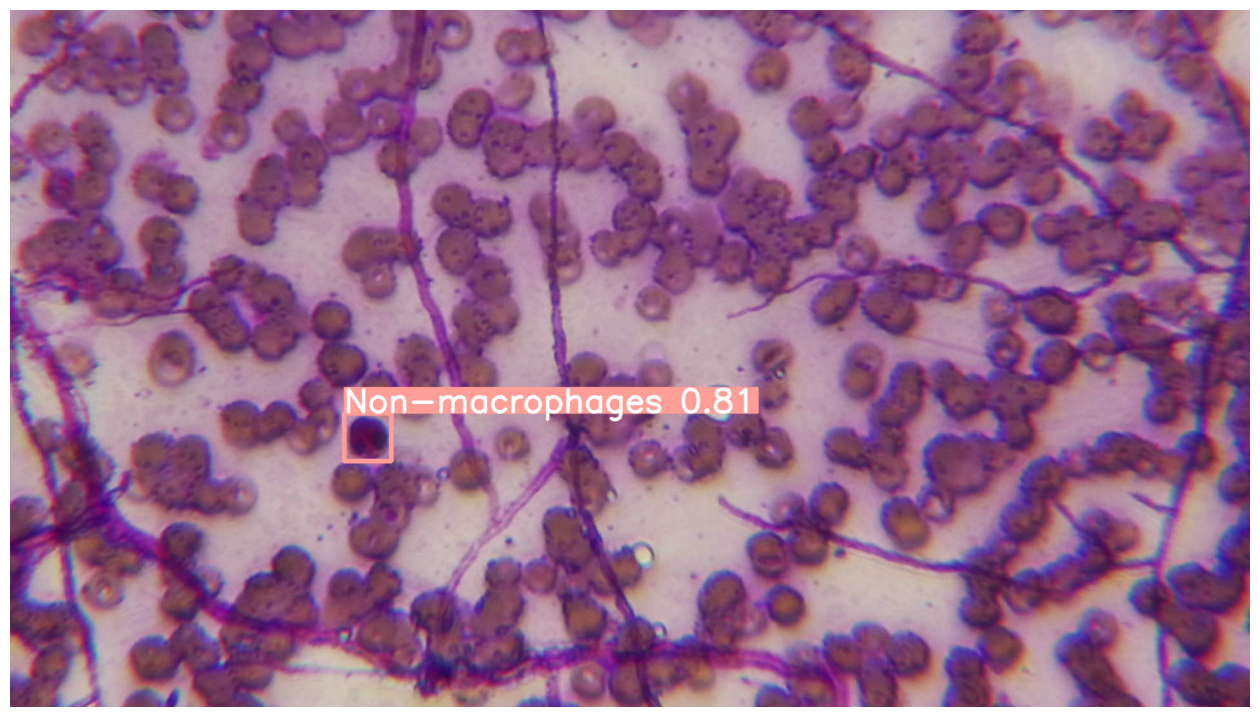

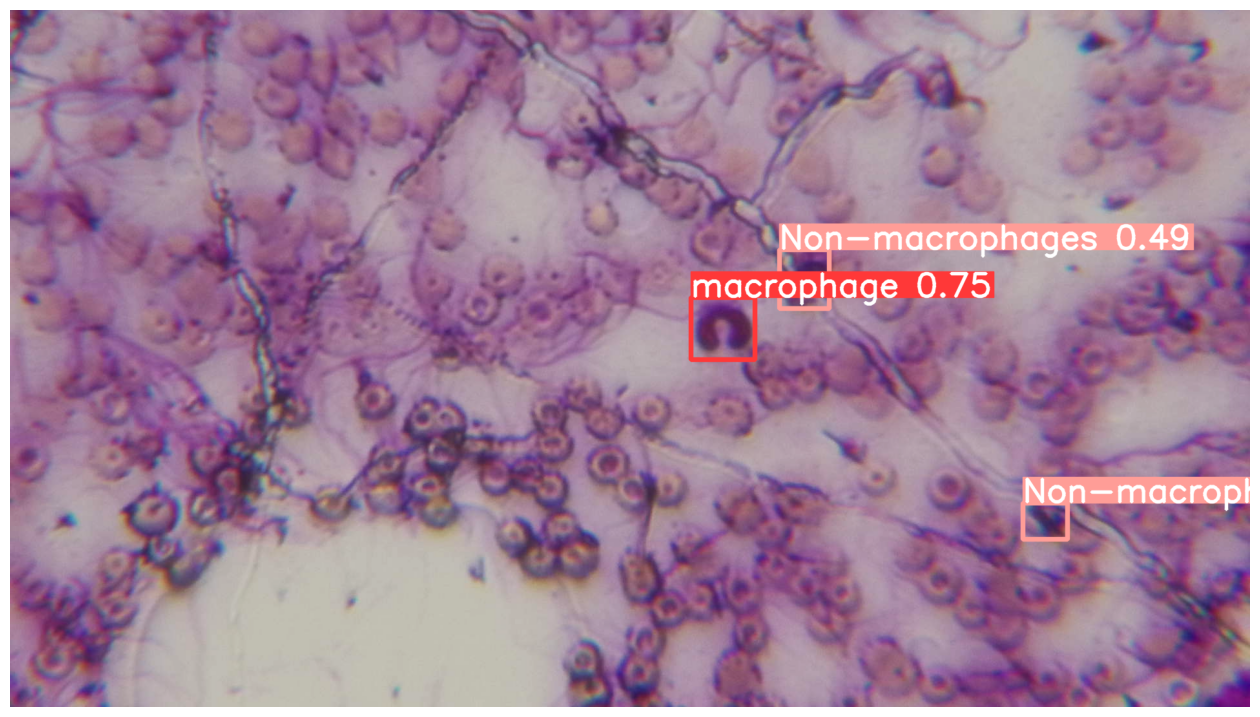

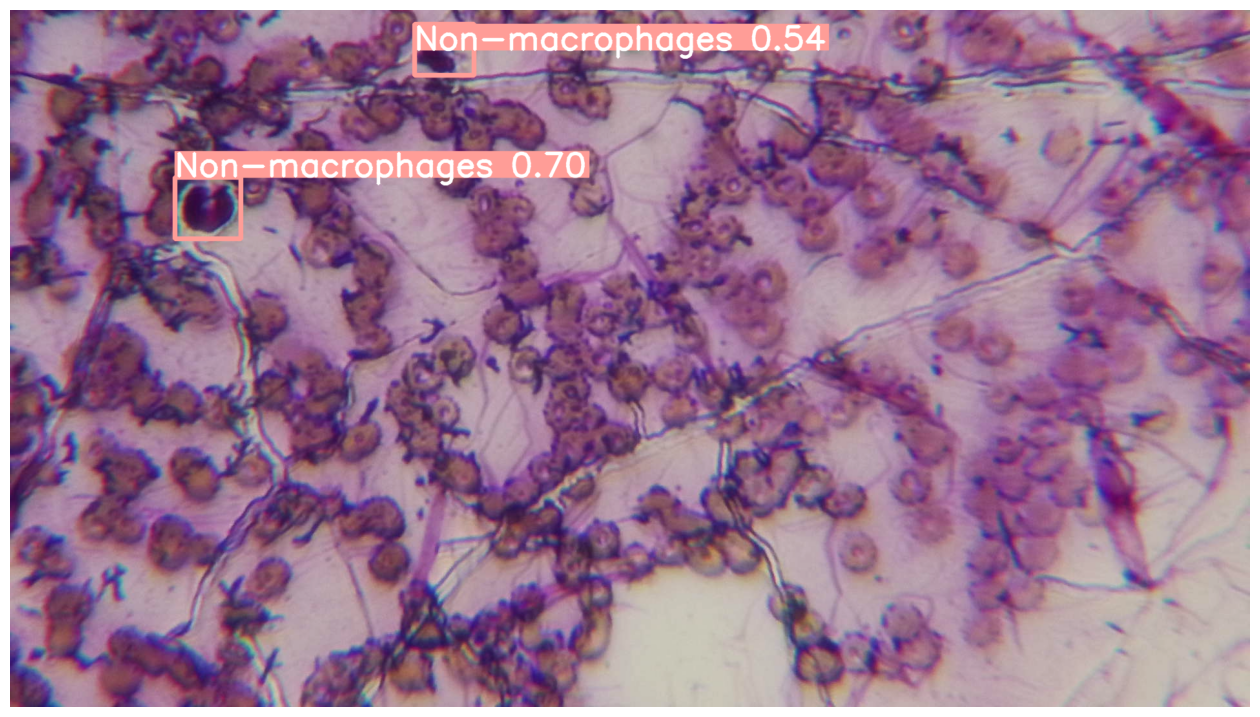

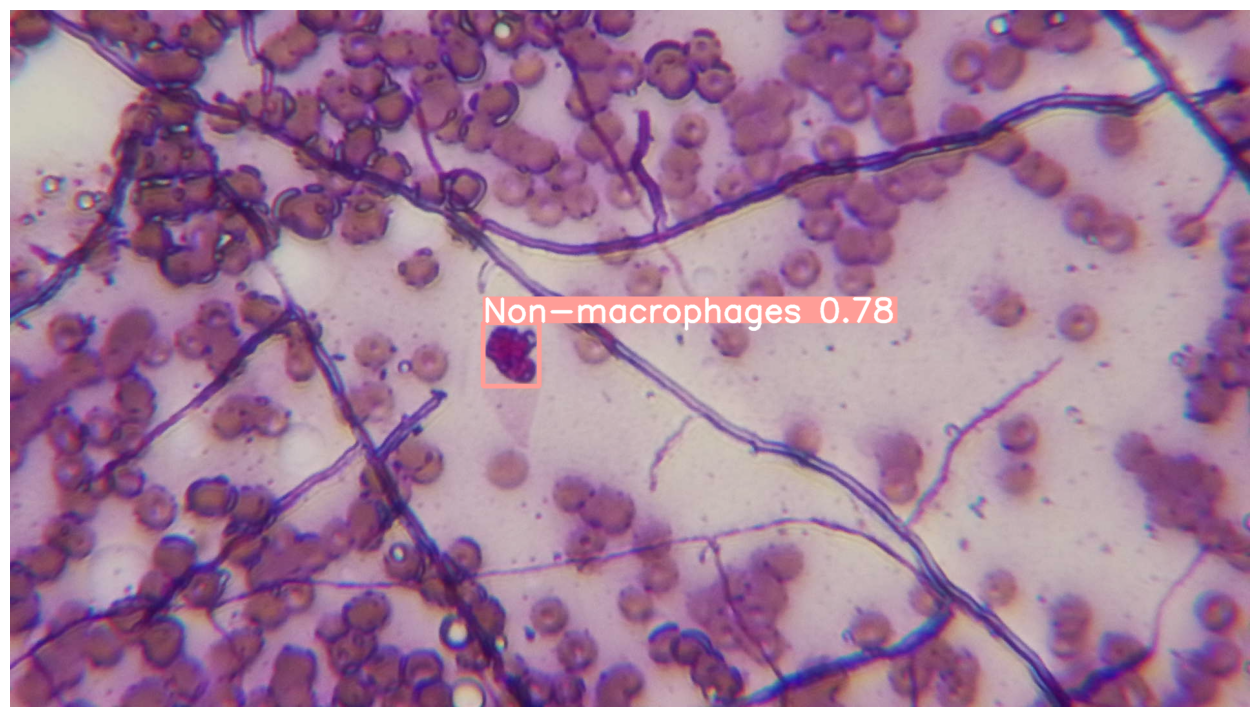

In [19]:
dir_predicoes = 'runs/detect/predict3/'
caminhos = [os.path.join(dir_predicoes, f) for f in os.listdir(dir_predicoes)]
for caminho_imagem in caminhos:
  imagem = cv2.imread(caminho_imagem)
  mostrar(imagem)